# Podstawy sztucznej inteligencji: przestrzeń stanów, BFS, DFS, heurystyki i A*

Ten notatnik jest przeznaczony do pracy w **Google Colab**.

## Cele
Po wykonaniu notatnika student powinien:
- rozumieć pojęcie **przestrzeni stanów**,
- umieć reprezentować problem jako graf,
- rozumieć działanie **BFS** i **DFS**,
- wiedzieć, czym jest **heurystyka**,
- rozumieć funkcję $f(n) = g(n) + h(n)$ używaną w algorytmie **A\***,
- potrafić porównać BFS, DFS i A* pod względem:
  - kompletności,
  - optymalności,
  - liczby odwiedzonych stanów,
  - wykorzystania informacji o celu.


## 1. Problem jako przestrzeń stanów

W wielu klasycznych problemach AI nie pytamy od razu:

> „Jak wygląda rozwiązanie?”

Zamiast tego definiujemy:

1. **stan początkowy**,
2. **zbiór możliwych stanów**,
3. **operatory / akcje**, które zmieniają stan,
4. **test celu**,
5. opcjonalnie **koszt przejścia**.

Przykłady:
- znalezienie drogi na mapie,
- układanka 8-puzzle,
- szachy,
- planowanie działań robota,
- rozwiązanie problemu logicznego.

W tym notatniku wykorzystamy prosty świat w postaci **siatki 2D**.

- `0` – pole dostępne,
- `1` – przeszkoda,
- `S` – start,
- `G` – cel.


In [284]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..##.##.#B#B#.",
    "#P.P#..#.#.#.#",
    ".###B##B#.#.##",
    ".......###.#.P",
    "...#...#..#P..",
    ".#...####..P..",
    "###...#....P.#",
    "......##.B...#",
    "#.######..####",
    "#.##..........",
]

#grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

# Rozwiązanie zadania 5

grid = []
koszty = {}
r = 0
c = 0
for wiersz in MAPA:
  grid.append([])

  for ch in wiersz:
    if ch == "#":
      grid[r].append(1)
    elif ch == "P":
      grid[r].append(0)
      koszty[(r, c)] = 3
    elif ch == "B":
      grid[r].append(0)
      koszty[(r, c)] = 5
    else:
      grid[r].append(0)
      koszty[(r, c)] = 1
    c += 1

  r += 1
  c = 0

del r
del c

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])
print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)



### Reprezentacja stanu

Stanem będzie para:

```python
(wiersz, kolumna)
```

Np. `(2, 4)` oznacza komórkę w trzecim wierszu i piątej kolumnie.

Dozwolone akcje:
- góra,
- dół,
- lewo,
- prawo.

Nie wolno:
- wyjść poza planszę,
- wejść na przeszkodę.


In [285]:

def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (0, -1),  # lewo
        (0, 1),   # prawo
        (1, 0),   # dół

        # Rozwiązanie zadania 4
        (-1, -1), # lewa góra
        (-1, 1),  # prawa góra
        (1, -1),  # lewy dół
        (1, 1),   # prawy dół
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


print("Sąsiedzi startu:", get_neighbors(start))


Sąsiedzi startu: [(0, 1), (1, 1)]



## 2. Wizualizacja problemu


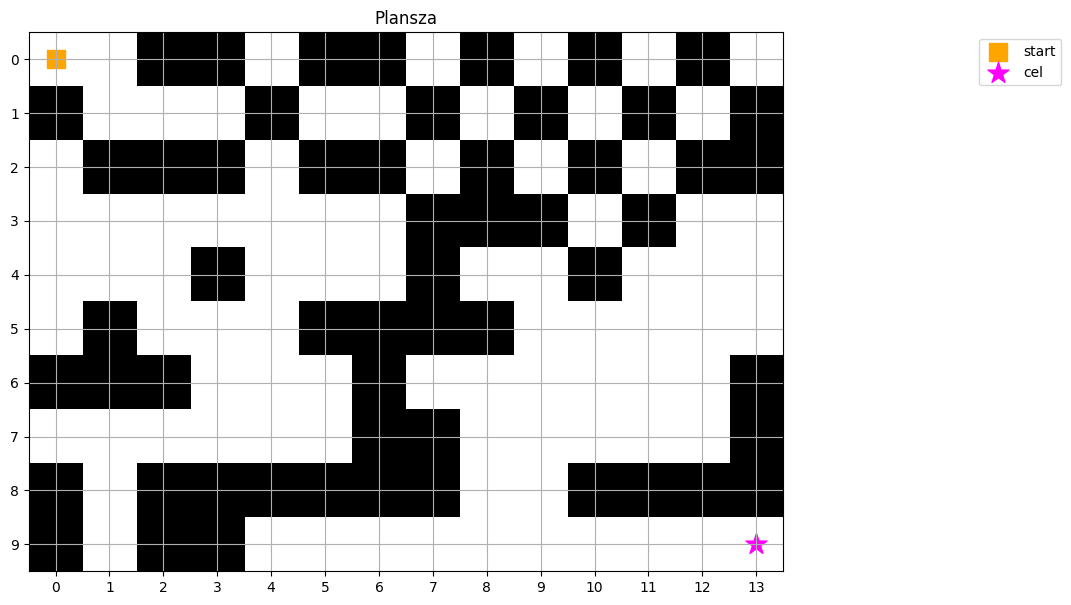

In [286]:
def draw_grid(path=None, visited=None, title="Plansza"):
    img = [[1 if cell == 0 else 0 for cell in row] for row in grid]

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap="gray", origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]
        # kolor punktu = kolejność odwiedzin (ciemny – wcześnie, jasny – późno)
        sc = plt.scatter(vc, vr, c=range(len(visited)), cmap="viridis",
                         s=110, alpha=0.85, label="odwiedzone")
        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]
        plt.plot(pc, pr, color="red", marker="o", linewidth=3, label="ścieżka")

    plt.scatter(start[1], start[0], s=180, marker="s", color="orange", label="start")
    plt.scatter(goal[1], goal[0], s=250, marker="*", color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()


draw_grid()


# 3. BFS — Breadth-First Search

BFS przeszukuje graf **warstwami**.

Najpierw:
- start,
- potem stany odległe o 1 krok,
- potem o 2 kroki,
- potem o 3 kroki,
- itd.

BFS wykorzystuje **kolejkę FIFO**.

### Ważna własność

Jeśli wszystkie przejścia mają taki sam koszt, BFS znajduje **najkrótszą ścieżkę**.

Schemat:

```text
kolejka = [start]

dopóki kolejka nie jest pusta:
    pobierz pierwszy element
    jeżeli to cel:
        zakończ
    dodaj nieodwiedzonych sąsiadów na koniec kolejki
```


BFS - długość ścieżki: 19
BFS - odwiedzone stany: 83
BFS - ścieżka: [(0, 0), (0, 1), (1, 2), (1, 3), (0, 4), (1, 5), (1, 6), (0, 7), (1, 8), (2, 9), (3, 10), (4, 9), (5, 9), (6, 9), (7, 9), (8, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


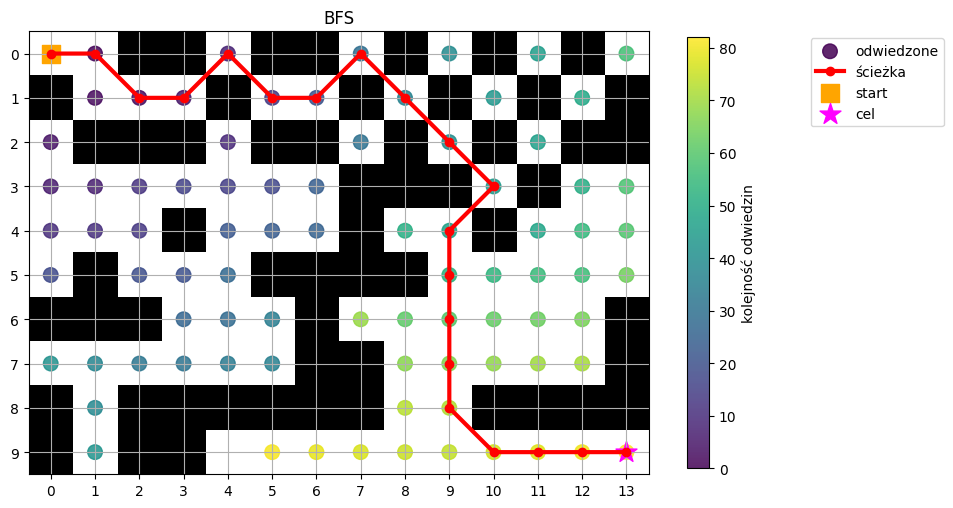

In [287]:

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")



### Pytania

1. Dlaczego BFS używa kolejki, a nie stosu?
2. Dlaczego BFS znajduje najkrótszą ścieżkę przy jednakowych kosztach przejść?
3. Co się stanie z pamięcią BFS, gdy przestrzeń stanów będzie bardzo duża?


# 4. DFS — Depth-First Search

DFS wybiera jedną gałąź i idzie **jak najgłębiej**.

Wykorzystuje:
- stos,
- albo rekurencję.

DFS nie gwarantuje najkrótszej ścieżki.

W wersji **bez** zapamiętywania odwiedzonych stanów DFS zużywa znacznie mniej pamięci niż BFS – pamięta tylko bieżącą gałąź. W naszej implementacji (ze zbiorem `visited`) oba algorytmy mogą w najgorszym razie pamiętać wszystkie stany.

DFS - długość ścieżki: 41
DFS - odwiedzone stany: 66
DFS - ścieżka: [(0, 0), (1, 1), (2, 0), (3, 1), (4, 2), (5, 3), (6, 4), (7, 5), (7, 4), (6, 5), (5, 4), (6, 3), (5, 2), (4, 1), (3, 2), (3, 3), (4, 4), (3, 5), (4, 6), (4, 5), (3, 6), (2, 7), (1, 8), (2, 9), (3, 10), (4, 11), (5, 12), (6, 11), (7, 12), (7, 11), (6, 12), (5, 13), (4, 12), (5, 11), (6, 10), (7, 9), (8, 8), (9, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


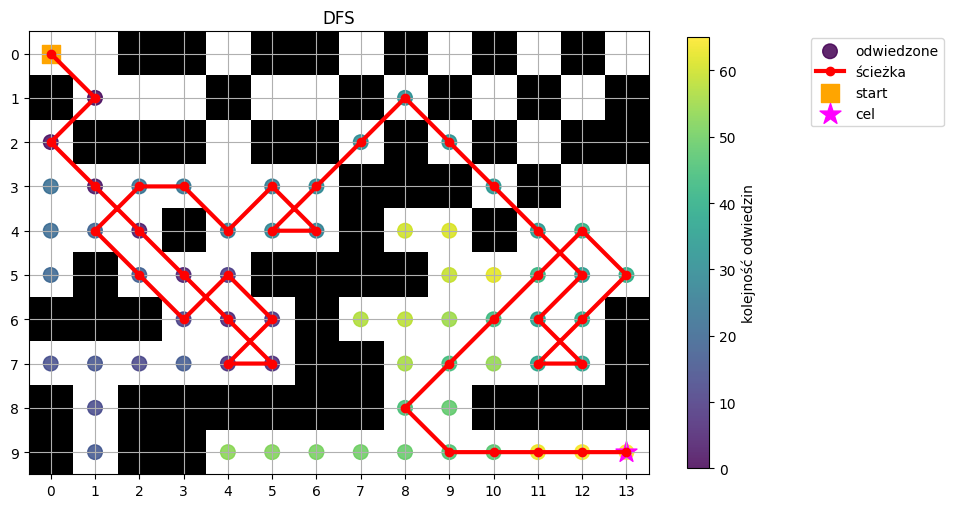

In [288]:
def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))
print("DFS - ścieżka:", dfs_path)

draw_grid(dfs_path, dfs_visited, "DFS")

### BFS vs DFS

| Cecha | BFS | DFS |
|---|---|---|
| Struktura danych | kolejka | stos |
| Strategia | wszerz | w głąb |
| Najkrótsza ścieżka | tak, dla równych kosztów | nie |
| Kompletność | zwykle tak | zależy od przestrzeni |
| Pamięć | duża (cała „warstwa” w kolejce) | mała tylko w wersji bez zbioru odwiedzonych |
| Informacja o celu | nie | nie |

Ani BFS, ani DFS nie „wiedzą”, **w którą stronę znajduje się cel**.


# 5. Heurystyka

Heurystyka to funkcja, która próbuje oszacować:

> „Jak daleko jestem od celu?”

Zapisujemy ją jako:

$$
h(n)
$$

gdzie `n` jest aktualnym stanem.

Dobra heurystyka:
- jest szybka do policzenia,
- koreluje z rzeczywistym kosztem dojścia do celu,
- pomaga ograniczyć liczbę analizowanych stanów.

## Odległość Manhattan

Dla ruchów góra/dół/lewo/prawo:

$$
h(n) = |x_n - x_g| + |y_n - y_g|
$$


In [289]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def euclidean(a, b):
    return math.sqrt((a[0] - b[0])**2 + (a[1] - b[1])**2)


examples = [(0, 0), (4, 6), (7, 10), (9, 12)]

for state in examples:
    print(
        state,
        "Manhattan =", round(manhattan(state, goal), 2),
        "Euclidean =", round(euclidean(state, goal), 2)
    )

(0, 0) Manhattan = 22 Euclidean = 15.81
(4, 6) Manhattan = 12 Euclidean = 8.6
(7, 10) Manhattan = 5 Euclidean = 3.61
(9, 12) Manhattan = 1 Euclidean = 1.0



### Heurystyka nie musi być idealna

Heurystyka nie rozwiązuje problemu.

Może nawet „nie widzieć” przeszkód.

Dla przykładu odległość Manhattan może wskazywać, że cel jest blisko, mimo że między stanem a celem znajduje się ściana.

Jej rolą jest **ukierunkowanie wyszukiwania**.



# 6. Greedy Best-First Search

Zanim przejdziemy do A*, zobaczmy prostszy algorytm.

Greedy Best-First Search wybiera stan z najmniejszą wartością:

$$
h(n)
$$

Czyli pyta wyłącznie:

> „Który stan wygląda na najbliższy celu?”

Nie bierze pod uwagę kosztu już przebytej drogi.


Greedy - długość ścieżki: 19
Greedy - odwiedzone stany: 26


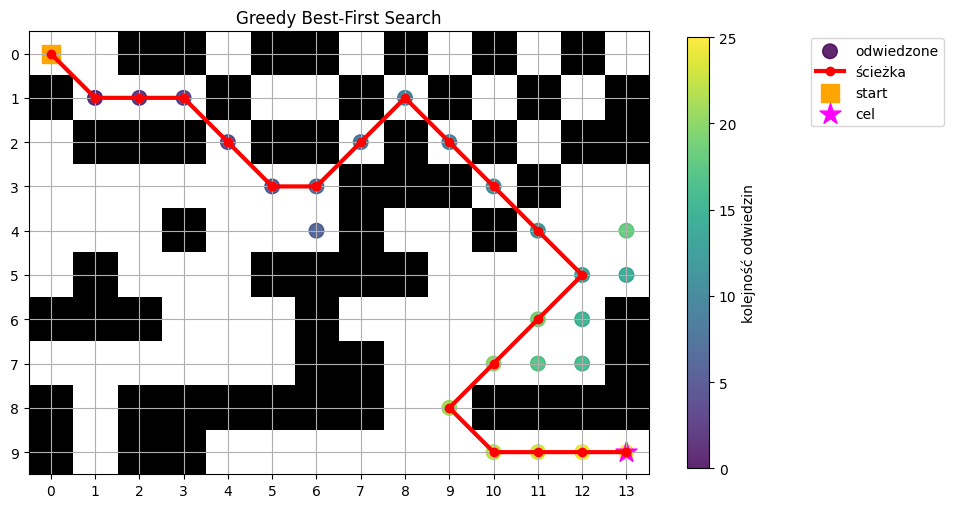

In [290]:
def greedy_best_first(start, goal):
    # W kopcu trzymamy (h, stan, rodzic) – rodzica zapisujemy przy zdjęciu z kopca,
    # tak jak w DFS.
    heap = []
    heapq.heappush(heap, (manhattan(start, goal), start, None))

    visited = set()
    parent = {}
    visit_order = []

    while heap:
        _, current, current_parent = heapq.heappop(heap)

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                heapq.heappush(
                    heap,
                    (manhattan(neighbor, goal), neighbor, current)
                )

    return None, visit_order


greedy_path, greedy_visited = greedy_best_first(start, goal)

print("Greedy - długość ścieżki:", len(greedy_path) - 1)
print("Greedy - odwiedzone stany:", len(greedy_visited))

draw_grid(greedy_path, greedy_visited, "Greedy Best-First Search")


# 7. A*

A* łączy dwie informacje.

## Koszt od startu

$$
g(n)
$$

czyli rzeczywisty koszt dojścia od startu do aktualnego stanu.

## Szacowany koszt do celu

$$
h(n)
$$

## Funkcja oceny

$$
f(n) = g(n) + h(n)
$$

A* wybiera stan o najmniejszej wartości `f(n)`.

Można to interpretować tak:

> „Szukam rozwiązania, które jest jednocześnie tanie do tej pory i wygląda obiecująco na przyszłość.”


A* - koszt: 25.55634918610405
A* - odwiedzone stany: 59
A* - ścieżka: [(0, 0), (0, 1), (1, 2), (1, 3), (0, 4), (1, 5), (1, 6), (0, 7), (1, 8), (2, 9), (3, 10), (4, 9), (5, 10), (6, 10), (7, 10), (8, 9), (9, 10), (9, 11), (9, 12), (9, 13)]


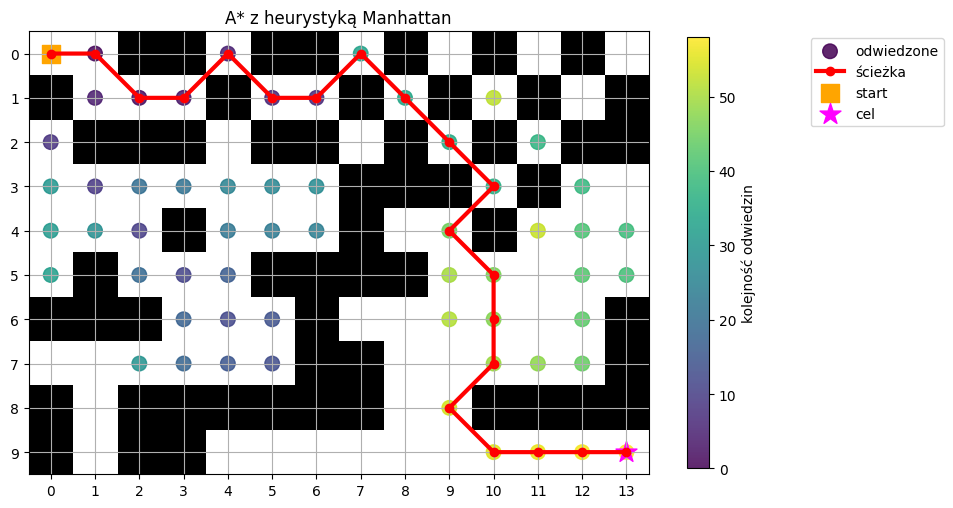

In [291]:
def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            # Rozwiązanie zadań 4 i 5
            #tentative_g = g_score[current] + 1
            tentative_g = g_score[current] + math.sqrt((neighbor[0] - current[0])**2 + (neighbor[1] - current[1])**2) * koszty[neighbor]

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))
print("A* - ścieżka:", astar_path)

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")


# 8. Porównanie algorytmów

Sprawdźmy:
- długość znalezionej ścieżki,
- liczbę odwiedzonych stanów.


In [292]:

results = [
    ("BFS", len(bfs_path) - 1, len(bfs_visited)),
    ("DFS", len(dfs_path) - 1, len(dfs_visited)),
    ("Greedy", len(greedy_path) - 1, len(greedy_visited)),
    ("A*", len(astar_path) - 1, len(astar_visited)),
]

print(f"{'Algorytm':<12} {'Długość ścieżki':<18} {'Odwiedzone stany'}")
print("-" * 50)

for name, path_len, visited_count in results:
    print(f"{name:<12} {path_len:<18} {visited_count}")


Algorytm     Długość ścieżki    Odwiedzone stany
--------------------------------------------------
BFS          19                 83
DFS          41                 66
Greedy       19                 26
A*           19                 59



## Interpretacja

Typowy wzorzec:

- **BFS** – znajduje drogę optymalną, ale może analizować wiele stanów,
- **DFS** – może szybko znaleźć rozwiązanie, ale nie musi być ono najlepsze,
- **Greedy** – mocno kieruje się ku celowi, ale może podjąć złą lokalną decyzję,
- **A\*** – łączy koszt dotychczasowy i heurystykę.

A* jest jednym z najważniejszych klasycznych algorytmów wyszukiwania w AI.


# 9. Co oznacza „dobra heurystyka”?

Dla A* szczególnie ważne jest pojęcie heurystyki **dopuszczalnej**.

Heurystyka jest dopuszczalna, jeśli nigdy nie przeszacowuje rzeczywistego kosztu dojścia do celu:

$$
h(n) \leq h^*(n)
$$

gdzie:

- $h(n)$ – nasza heurystyka,
- $h^*(n)$ – rzeczywisty minimalny koszt dojścia do celu.

Dla ruchów tylko:
- góra,
- dół,
- lewo,
- prawo,

odległość Manhattan jest naturalną heurystyką.

**Uwaga:** implementacja A* z tego notatnika (ze zbiorem `closed`, bez ponownego otwierania stanów) gwarantuje optymalność dla heurystyki **spójnej**:

$$
h(n) \leq c(n, n') + h(n')
$$

dla każdego sąsiada $n'$ stanu $n$. Każda heurystyka spójna jest dopuszczalna. Odległość Manhattan i odległość euklidesowa na naszej siatce są spójne.

In [293]:

astar_euclidean_path, astar_euclidean_visited, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

print("A* Manhattan - odwiedzone stany:", len(astar_visited))
print("A* Euclidean - odwiedzone stany:", len(astar_euclidean_visited))


A* Manhattan - odwiedzone stany: 59
A* Euclidean - odwiedzone stany: 68



# 10. Eksperyment: A* bez heurystyki

Co się stanie, jeśli:

$$
h(n) = 0
$$

Wtedy:

$$
f(n) = g(n)
$$

A* zachowuje się wtedy jak algorytm Dijkstry.

Przy jednakowych kosztach przejść jego zachowanie jest bardzo zbliżone do BFS.


A* z h=0 - odwiedzone stany: 84
BFS       - odwiedzone stany: 83


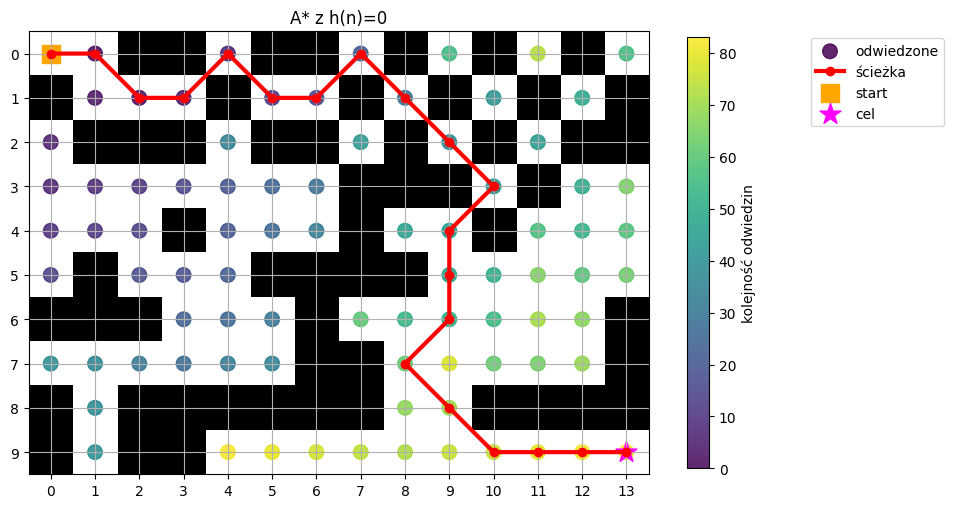

In [313]:

def zero_heuristic(a, b):
    return 0


path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("BFS       - odwiedzone stany:", len(bfs_visited))

draw_grid(
    path_h0,
    visited_h0,
    "A* z h(n)=0"
)


# 11. Eksperyment: zbyt agresywna heurystyka

Spróbujmy:

$$
h'(n) = 3 \cdot h(n)
$$

Taka heurystyka może przeszacowywać rzeczywisty koszt.

Wtedy A* może odwiedzać mniej stanów, ale traci gwarancję optymalności.


Koszt: 29.798989873223338
Odwiedzone stany: 46


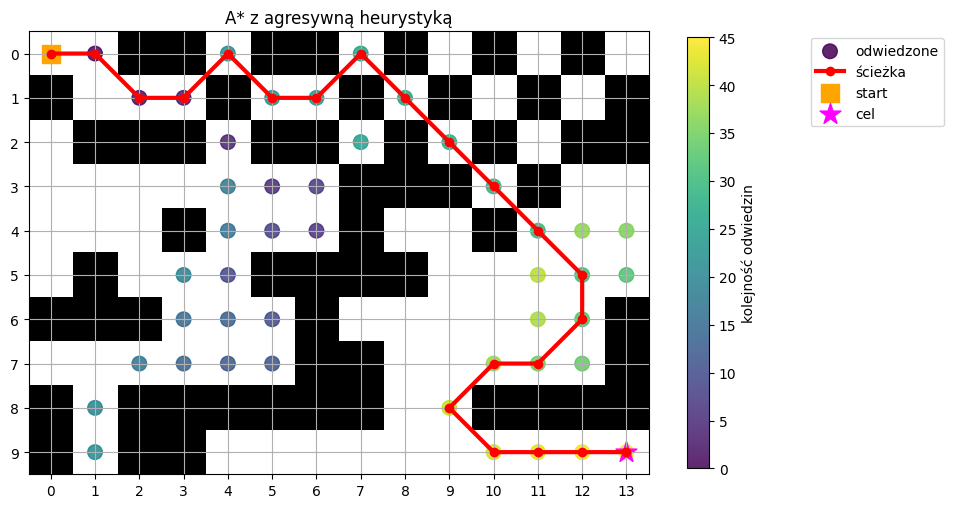

In [295]:

def aggressive_heuristic(a, b):
    return 3 * manhattan(a, b)


aggressive_path, aggressive_visited, aggressive_cost = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

print("Koszt:", aggressive_cost)
print("Odwiedzone stany:", len(aggressive_visited))

draw_grid(
    aggressive_path,
    aggressive_visited,
    "A* z agresywną heurystyką"
)



# 12. Zadania dla studentów

## Zadanie 1 — zmiana kolejności DFS

W funkcji `get_neighbors()` zmień kolejność ruchów.

Sprawdź:
- czy DFS znajdzie inną ścieżkę,
- czy zmieni się liczba odwiedzonych stanów.

Wyjaśnij dlaczego.

---

## Zadanie 2 — nowa mapa

Zmodyfikuj przeszkody w `grid`.

Stwórz mapę, na której:
- BFS odwiedzi dużo stanów,
- A* odwiedzi wyraźnie mniej stanów.

---

## Zadanie 3 — własna heurystyka

Napisz heurystykę:

```python
def my_heuristic(a, b):
    ...
```

Porównaj ją z:
- Manhattan,
- Euclidean,
- `h(n)=0`.

---

## Zadanie 4 — ruch po przekątnej

Dodaj ruchy:

```text
↖ ↑ ↗
←   →
↙ ↓ ↘
```

Odpowiedz:

1. Czy Manhattan nadal jest najlepszym wyborem?
2. Jaką heurystykę zastosować?
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?

---

## Zadanie 5 — przeszkody z różnym kosztem

Załóż, że wejście na:
- zwykłe pole kosztuje `1`,
- piasek kosztuje `3`,
- bagno kosztuje `5`.

Zmodyfikuj A*, aby uwzględniał różne koszty przejść.

Czy BFS nadal gwarantuje znalezienie najtańszej ścieżki?

---

## Zadanie 6 — pytanie koncepcyjne

Wyjaśnij własnymi słowami różnicę między:

$$
g(n)
$$

a

$$
h(n)
$$

w algorytmie A*.


# 13. Zadanie rozszerzone — 8-puzzle

Rozważ układankę:

```text
_ 2 4
3 6 5
7 1 8
```

Stan można zapisać jako:

```python
(0, 2, 4,
 3, 6, 5,
 7, 1, 8)
```

gdzie `0` oznacza puste pole.

Stan docelowy:

```python
(1, 2, 3,
 4, 5, 6,
 7, 8, 0)
```

### Zadanie

Zaimplementuj A* dla 8-puzzle.

Jako heurystykę wykorzystaj:

> sumę odległości Manhattan każdego kafelka od jego pozycji docelowej.

To klasyczny przykład problemu przeszukiwania przestrzeni stanów.

In [312]:
# Miejsce na rozwiązanie zadania 8-puzzle.

start_puzzle = (
    0, 2, 4,
    3, 6, 5,
    7, 1, 8
)

goal_puzzle = (
    1, 2, 3,
    4, 5, 6,
    7, 8, 0
)

n = len(start_puzzle)

def get_neighborsP(state):
  moves = [
      -3,   # góra
      3,    # dół
      -1,    # lewo
      1,   # prawo
  ]

  neighbors = []

  for move in moves:
    neighbor_state = state + move

    if 0 <= neighbor_state < n:
      neighbors.append(start_puzzle[neighbor_state])

  return neighbors

print("Sąsiedzi startu:", get_neighborsP(4))
# TODO:
# 1. napisz funkcję generującą sąsiadów,
# 2. napisz heurystykę Manhattan,
# 3. wykorzystaj A*.

Sąsiedzi startu: [2, 1, 3, 5]


# 14. Podsumowanie

Najważniejsze idee:

### Przestrzeń stanów
Problem AI można traktować jako zbiór stanów połączonych możliwymi akcjami.

### BFS
Przeszukuje wszerz i dla jednakowych kosztów gwarantuje najkrótszą ścieżkę.

### DFS
Przeszukuje w głąb i nie gwarantuje najlepszego rozwiązania. W wersji bez zapamiętywania odwiedzonych stanów potrzebuje znacznie mniej pamięci niż BFS.

### Heurystyka
Dostarcza dodatkowej wiedzy o tym, które stany wyglądają obiecująco.

### A*
Łączy:

$$
g(n)
$$

oraz

$$
h(n)
$$

w funkcji:

$$
f(n)=g(n)+h(n)
$$

Dzięki temu może znajdować optymalne rozwiązania znacznie bardziej efektywnie niż algorytmy niepoinformowane.


# 15. Pytania kontrolne

1. Co jest stanem w problemie wyszukiwania drogi?
2. Czym różni się BFS od DFS?
3. Dlaczego BFS może potrzebować dużo pamięci?
4. Co oznacza $g(n)$?
5. Co oznacza $h(n)$?
6. Co oznacza $f(n)$?
7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
8. Co oznacza, że heurystyka jest dopuszczalna?
9. Co się stanie w A*, gdy $h(n)=0$?
10. Czy A* zawsze jest szybszy od BFS?


#Rozwiązanie zadania 1

Depth First Search działa na tej zasadzie, że "idzie" jak najgłębiej w danym kierunku i jeżeli nie znajdzie dobrej trasy to się zawraca.

Zakładamy oryginalną mapę
```python
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]
```

W funkcji `get_neighbors()` kolejność ruchów ma znaczenie. <br>
Pierwotny zestaw:
```python
moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]
```

Według algorytmu
```python
for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))
```
dodaje do listy `neighbours` (jeżeli są) sąsiada najpierw z góry, dołu, lewej i na końcu z prawej.

W kodzie DFS z punktu 4 widać, że algorytm bierze tych sąsiadów w kolejności odwrotnej z powodu użycia metody `pop()` na liście `stack`, do której trafiają sąsiedzi z `get_neighbors()`, dlatego po włączeniu wizualizacji widzimy, że wytyczona ścieżka kieruje się głównie w prawo kiedy może.


Kiedy ustawimy ruch w dół jako ostatni w liście:
```python
moves = [
        (-1, 0),  # góra
        (0, -1),  # lewo
        (0, 1),   # prawo
        (1, 0),   # dół
    ]   
```
to algorytm zacznie poruszać się właśnie w dół, a nie w prawo **co spowoduje znalezienie innej ścieżki oraz zmianę liczby odwiedzonych stanów**.

#Rozwiązanie zadania 2
```python
MAPA = [
    "..............",
    ".############.",
    ".#............",
    ".#..........#.",
    ".#..........#.",
    ".#..........#.",
    ".#..........#.",
    ".#..........#.",
    ".#..........#.",
    "..............",
]
```
BFS - odwiedzone stany: 115 <br>
A* - odwiedzone stany: 44 <br>
A* z agresywną heurystyką - Odwiedzone stany: 23

#Rozwiązanie zadania 3

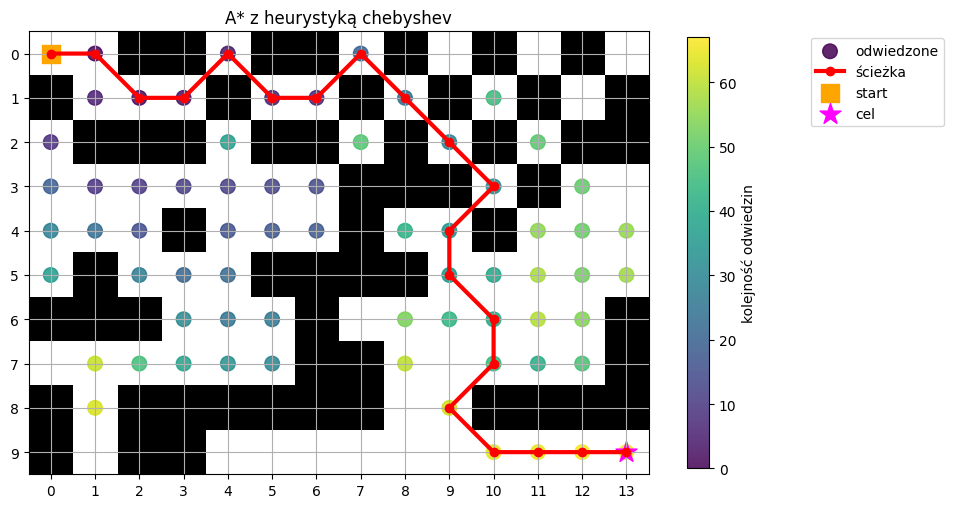

A* z chebyshev - odwiedzone stany: 68
A* z agresywną heurystyką - odwiedzone stany: 46
A* z h=0 - odwiedzone stany: 84
A* z manhattan - odwiedzone stany: 59
A* z euclidean - odwiedzone stany: 68


In [297]:
def chebyshev(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))

path_ch, visited_ch, _ = astar(
    start,
    goal,
    heuristic=chebyshev
)

path_ag, visited_ag, _ = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

path_h0, visited_h0, _ = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

path_man, visited_man, _ = astar(
    start,
    goal,
    heuristic=manhattan
)

path_eu, visited_eu, _ = astar(
    start,
    goal,
    heuristic=euclidean
)

draw_grid(
    path_ch,
    visited_ch,
    "A* z heurystyką chebyshev"
)

print("A* z chebyshev - odwiedzone stany:", len(visited_ch))
print("A* z agresywną heurystyką - odwiedzone stany:", len(visited_ag))
print("A* z h=0 - odwiedzone stany:", len(visited_h0))
print("A* z manhattan - odwiedzone stany:", len(visited_man))
print("A* z euclidean - odwiedzone stany:", len(visited_eu))

#Rozwiązanie zadania 4
```python
moves = [
    (-1, 0),  # góra
    (0, -1),  # lewo
    (0, 1),   # prawo
    (1, 0),   # dół
    
    (-1, -1), # lewa góra
    (-1, 1),  # prawa góra
    (1, -1),  # lewy dół
    (1, 1),   # prawy dół
]
```

In [298]:
_1, _2, cost_ch = astar(
    start,
    goal,
    heuristic=chebyshev
)

_1, _2, cost_ag = astar(
    start,
    goal,
    heuristic=aggressive_heuristic
)

_1, _2, cost_h0 = astar(
    start,
    goal,
    heuristic=zero_heuristic
)

_1, _2, cost_man = astar(
    start,
    goal,
    heuristic=manhattan
)

_1, _2, cost_eu = astar(
    start,
    goal,
    heuristic=euclidean
)

print("Koszt chebyshev:", cost_ch)
print("Koszt agresywnej heurystyki:", cost_ag)
print("Koszt zerowej heurystyki:", cost_h0)
print("Koszt manhattan:", cost_man)
print("Koszt euklidesa:", cost_eu)

Koszt chebyshev: 25.55634918610405
Koszt agresywnej heurystyki: 29.798989873223338
Koszt zerowej heurystyki: 25.55634918610405
Koszt manhattan: 25.55634918610405
Koszt euklidesa: 25.55634918610405


Na oryginalnej mapie
```python
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]
```
Użycie każdej heurystyki bez wyjątku wiązało się z kosztem wynoszącym 17.313708498984763 <br>
Uwzględniając ilość odwiedzonych stanów mamy taki ranking:
1. manhattan - 18
2. agresywna - 19
3. euklides - 43
4. chebyshev - 63
5. h=0 - 103

Zmieniając mapę na przykład na taką:

```python
MAPA = [
    "..##.##.#.#.#.",
    "#...#..#.#.#.#",
    ".###.##.#.#.##",
    ".......###.#..",
    "...#...#..#...",
    ".#...####.....",
    "###...#......#",
    "......##.....#",
    "#.######..####",
    "#.##..........",
]
```
Przy użyciu każdej heurystyki koszt wynosił tyle samo czyli 22.72792206135786, poza agresywną, która miała 24.384776310850242, czyli jest najmniej efektywna pod tym względem. <br>
Pod względem ilości odwiedzonych stanów:
1. agresywna - 37
2. manhattan - 62
3. euklides - 69
4. chebyshev - 70
5. h=0 - 83

<br>Czyli można wnioskować, że manhattan nadal jest najlepszym wyborem, chyba że zależy nam na jak najmniejszej ilości odwiedzonych stanów - wtedy agresywna heurystyka ma szansę z nim wygrać kosztem większego kosztu.

<br>Mimo zwiększenia kosztu do $\sqrt{2}$ podczasz przechodzenia po przekątnej, ogólny koszt trasy powinien się zmniejszyć.
Na przykład: używając tradycyjnych ruchów góra, dół, lewo, prawo dotarcie do punktu (1, 1) z punktu (0, 0) potrzebuje dwóch ruchów, czyli koszt równy 2, z kolei przejście na ukos do tego punktu wymaga tylko 1 ruchu o koszcie równym $\sqrt{2}$. Różnica może być jeszcze bardziej zauważalna z przeszkodami, jeśli byłaby taka sytuacja, że można się "prześlizgnąć" na ukos między ściankami.

#Rozwiązanie zadania 5
W punkcie 1 zmieniłem
```python
grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]
```
na
```python
grid = []
koszty = {}
r = 0
c = 0
for wiersz in MAPA:
  grid.append([])

  for ch in wiersz:
    if ch == "#":
      grid[r].append(1)
    elif ch == "P":
      grid[r].append(0)
      koszty[(r, c)] = 3
    elif ch == "B":
      grid[r].append(0)
      koszty[(r, c)] = 5
    else:
      grid[r].append(0)
      koszty[(r, c)] = 1
    c += 1

  r += 1
  c = 0

del r
del c
```
Trochę dłuższe niż jedna linijka, ale działa.
<br>W punkcjie 7, gdzie jest kod A* zmieniłem
```python
tentative_g = g_score[current] + 1
```
na
```python
tentative_g = g_score[current] + math.sqrt((neighbor[0] - current[0])**2 + (neighbor[1] - current[1])**2) * koszty[neighbor]
```
fragment
```python
math.sqrt((neighbor[0] - current[0])**2 + (neighbor[1] - current[1])**2)
```
jest do punktu 4, gdzie zmieniany jest koszt przejścia po przekątnej z 1 na $\sqrt{2}$, więc albo mamy koszt 1 * koszt danego pola, albo $\sqrt{2}$ * koszt danego pola.

<br>Kiedy mamy do czynienia z różnymi typami pól BFS już nie ma gwarancji znalezienie najkorzystniejszego rozwiązania, ponieważ w jego interesie leży tylko znalezienie jak najkrótszej drogi, a jak najkrótsza droga może się składać ze sporej ilości "piasku" czy "błota", co przegrałoby z trochę dłuższą ścieżką składającą się w większości ze zwykłych pól.

#Rozwiązanie zadania 6
## h(n)
to tak zwana heurystyka. Jest to funkcja, która na jakiś wybrany sposób liczy odległość między aktualnym stanem, a stanem końcowym. Jest to narzędzie wspomagające algorytm, które daje mu oszacowanie jak daleko od celu się jeszcze znajduje, ale nie uwzględnia w swoich obliczeniach przeszkód. Dzięki heurystyce możemy nakierować algorytm A*, żeby szukał w dobrym kierunku co daje nam niezawodność BFS w szukaniu najlepszej trasy oraz małą ilość przebytych stanów jak w dobrze ukierunkowanym DFS.

## g(n)
to koszt ścieżki, którą algorytm przebył do tej pory od punktu startowego.
Pomaga to znaleźć A* ścieżkę o najmniejszym koszcie.

#Odpowiedzi na pytania kontrolne
##1. Co jest stanem w problemie wyszukiwania drogi?
Stanem w problemie wyszukiwania drogi jest pozycja, w której w danym momencie znajduje się algorytm. Na przykład (0, 0) to pierwszy wiersz i pierwsza kolumna, (2, 3) to trzeci wiersz i czwarta kolumna, itd.
##2. Czym różni się BFS od DFS?
Breath First Search - breadth = szerokość, algorytm przeszukuje wszystkie dostępne punkty do sprawdzenia i na koniec układa z nich najlepszą ścieżkę. Działa skutecznie, ale wolno. <br>
Depth First Search - depth = głębokość, algorytm przeszukuje wszystkie punkty w okreśonym kierunku tak długo jak może, jeśli nie może to idzie w kolejnym określonym po nim kierunku. Działa różnie, może mu się poszczęścić, ale jeśli kolejność kierunków jest źle ustalona to może chwilę pobłądzić.
##3. Dlaczego BFS może potrzebować dużo pamięci?
Tak jak powyżej, BFS sprawdza wszystkie dostępne pozycje i na koniec układa z nich drogę, dlatego musi przechowywać w pamięci wszystkie te możliwości.
##4. Co oznacza  g(n) ?
Oznacza już policzony koszt przedostania się do aktualnego stanu ze stanu początkowego.
##5. Co oznacza  h(n) ?
Oznacza heurystykę czyli funkcję szacującą jak daleko znajduje się cel w porównaniu do aktualnego stanu.
##6. Co oznacza  f(n) ?
Oznacza funkcję łączącą g(n) i h(n), dokładniej mówiąc
$$
f(n) = g(n) + h(n)
$$
Używana jest w algorytmie A* do wyznaczenia najoptymalniejszej trasy.
##7. Dlaczego heurystyka może przyspieszyć wyszukiwanie?
Heurystyka ma za zadanie nadać poprawny kierunek szukania. Jak algorytm pójdzie do stanu, który ma większą odległość od celu niż poprzedni, to wie żeby poszukać też w drugą stronę.
##8. Co oznacza, że heurystyka jest dopuszczalna?
Oznacza taką heurystykę, która nie zwraca większej wartości odległości niż rzeczywista odległość aktualnego stanu od celu.
##9. Co się stanie w A*, gdy  h(n)=0 ?
Zachowuje się wtedy podobnie do BFS przeszukując wszystkie stany jakie się da. Wie tylko jak daleko jest od startu, ale nie wie jak blisko ma do celu.
##10. Czy A* zawsze jest szybszy od BFS?
Nie zawsze, zależy to od użytej heurystyki. Użycie h(n) = 0 na pewno może sprawić, że A* będzie tak samo szybkie jak BFS albo trochę wolniejsze.